# Applied Data Science Capstone — 4. EDA with Data Visualization

## Objective
Visualise the relationships between launch attributes and first-stage landing
success using matplotlib and seaborn. Charts are also saved to `../assets/`
for the final presentation.

In [1]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/dataset_spacex.csv")
df["Year"] = df["Date"].str[:4]
print("rows:", len(df))

/usr/local/lib/python3.12/dist-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


rows: 90


### 1. Payload mass vs. flight number, coloured by landing outcome

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=df, x="FlightNumber", y="PayloadMass", hue="Class",
                palette={1: "tab:green", 0: "tab:red"}, ax=ax, s=60)
ax.set_title("Payload mass vs. flight number (green = landed successfully)")
ax.set_xlabel("Flight number"); ax.set_ylabel("Payload mass (kg)")
fig.tight_layout(); fig.savefig("../assets/payload_vs_flight.png", dpi=120)
print("saved ../assets/payload_vs_flight.png")

saved ../assets/payload_vs_flight.png


Observation: later flights (higher flight numbers, Block 5 era) cluster toward
successful landings; very heavy payloads (> ~10 t) show a lower success share —
recovery propellant trades against payload.

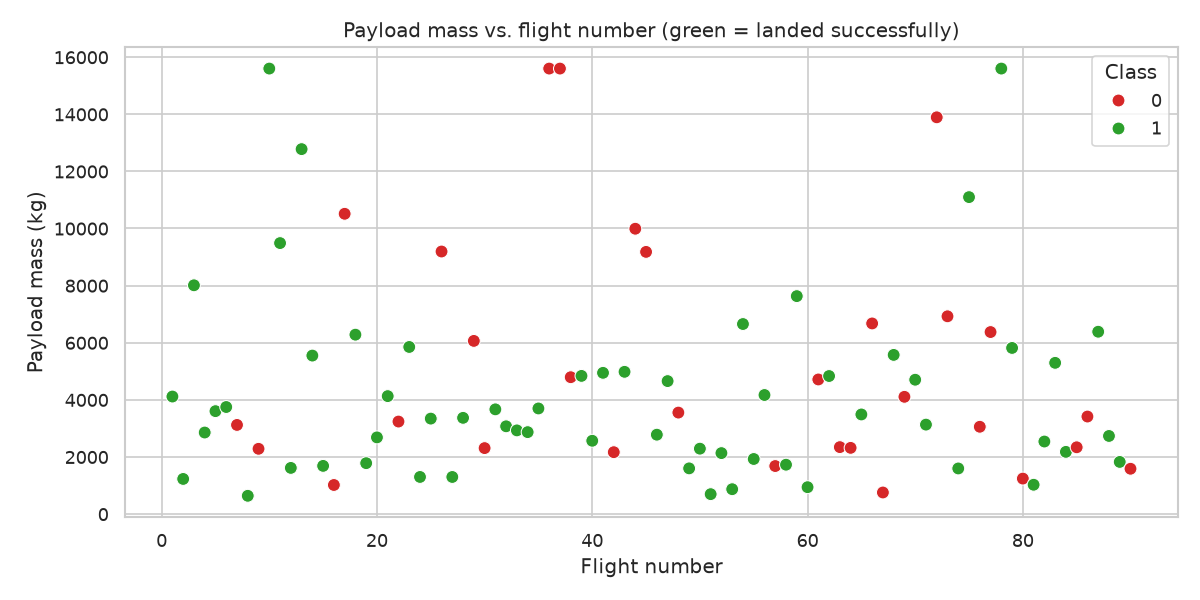

In [3]:
from IPython.display import Image
Image("../assets/payload_vs_flight.png")

### 2. Landing success rate by orbit

In [4]:
rate_orbit = df.groupby("Orbit")["Class"].mean().mul(100).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
rate_orbit.plot.barh(ax=ax, color="steelblue")
ax.set_title("First-stage landing success rate by orbit")
ax.set_xlabel("Success rate (%)")
for i, v in enumerate(rate_orbit):
    ax.text(v + 0.5, i, f"{v:.0f}%", va="center", fontsize=9)
fig.tight_layout(); fig.savefig("../assets/success_by_orbit.png", dpi=120)
print(rate_orbit.round(1).to_string())

Orbit
GEO      25.0
HEO      50.0
PO       50.0
ES-L1    66.7
GTO      66.7
ISS      66.7
MEO      66.7
SSO      66.7
VLEO     81.8
LEO      90.0


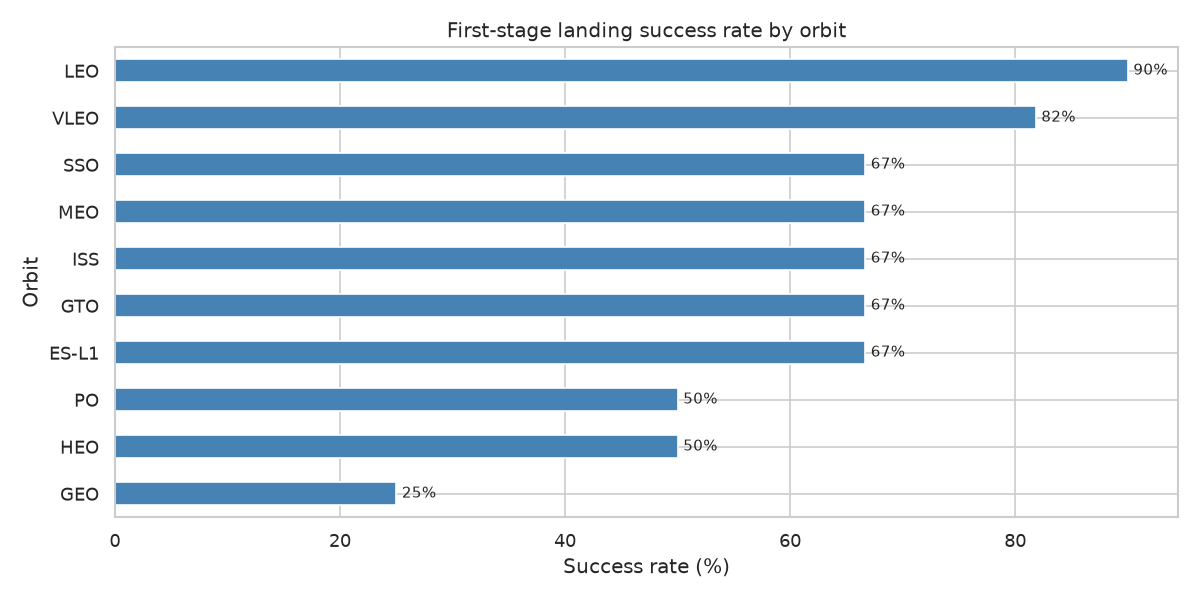

In [5]:
Image("../assets/success_by_orbit.png")

### 3. Landing success rate by launch site

In [6]:
rate_site = df.groupby("LaunchSite")["Class"].mean().mul(100).sort_values()
fig, ax = plt.subplots(figsize=(10, 4))
rate_site.plot.barh(ax=ax, color="darkorange")
ax.set_title("First-stage landing success rate by launch site")
ax.set_xlabel("Success rate (%)")
fig.tight_layout(); fig.savefig("../assets/success_by_site.png", dpi=120)
print(rate_site.round(1).to_string())

LaunchSite
KSC LC-39A      59.1
VAFB SLC-4E     60.0
CCAFS SLC-40    66.7
CCAFS LC-40     78.3


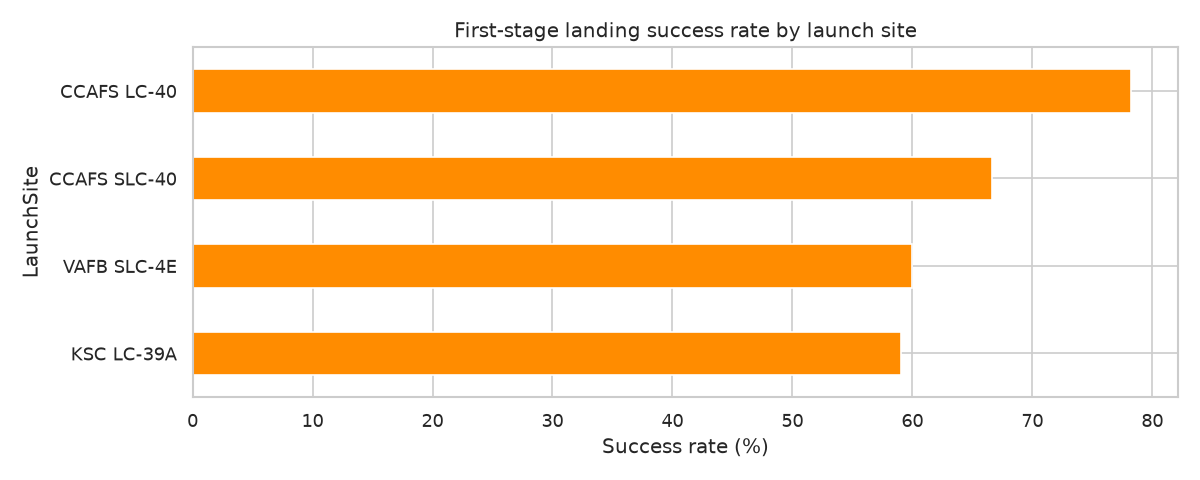

In [7]:
Image("../assets/success_by_site.png")

### 4. Launches and success rate per year

In [8]:
yearly = df.groupby("Year").agg(launches=("Class", "size"),
                                success_rate=("Class", "mean"))
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(yearly.index, yearly["launches"], color="lightsteelblue", label="launches")
ax1.set_ylabel("Launches"); ax1.set_xlabel("Year")
ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly["success_rate"].mul(100), "o-", color="crimson",
         label="success rate")
ax2.set_ylabel("Landing success rate (%)")
ax1.set_title("Launch cadence and landing success rate by year")
fig.tight_layout(); fig.savefig("../assets/yearly_trend.png", dpi=120)
print(yearly.round(2).to_string())

      launches  success_rate
Year                        
2010         1          1.00
2011         3          1.00
2012         1          0.00
2013         3          0.33
2014         5          0.60
2015         9          0.78
2016         7          0.86
2017         9          0.56
2018         6          0.83
2019         8          0.75
2020        13          0.46
2021         7          1.00
2022         8          0.50
2023        10          0.60


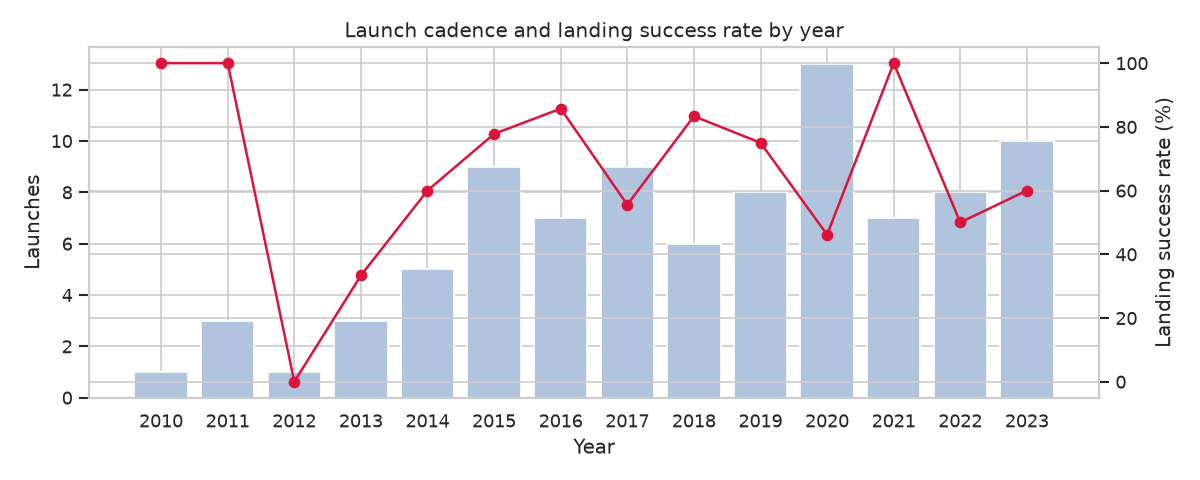

In [9]:
Image("../assets/yearly_trend.png")

### Findings
* Success rate improves markedly after ~2016 as landing procedures mature.
* LEO/ISS/VLEO missions recover boosters far more often than GTO/GEO missions.
* Payload mass alone does not decide the outcome — the orbit/energy requirement
  and booster block matter more (confirmed in the ML notebook).